# MAI-Image Family Walkthrough

<p align="center">
  <img src="../../.github/images/banners/mai-image-family-walkthrough.png" alt="MAI-Image family walkthrough: Flash for volume, MAI-Image-2.6 for fidelity" width="900" />
</p>

The latest MAI image models on Microsoft Foundry, each on the job it fits: Flash for volume, MAI-Image-2.6 for careful edits and a consistent character.

| | |
|---|---|
| Models | [MAI-Image-2.6](../../4-models/mai-image-2.6/) · [MAI-Image-2.6-Flash](../../4-models/mai-image-2.6-flash/) |
| Publisher | Microsoft AI |
| Capability | [Image Generation](../../3-primers/image-generation.md) |
| Docs | [Use MAI image models in Microsoft Foundry](https://learn.microsoft.com/azure/foundry/foundry-models/how-to/use-foundry-models-mai-image) |
| Deployments | Both models in one Foundry project |
| Pricing | [MAI model pricing](https://aka.ms/MAIModelPricing) |
| Env vars | `MICROSOFT_FOUNDRY_ENDPOINT` (or `MAI_IMAGE_ENDPOINT`), `AZURE_MAI_IMAGE_26_DEPLOYMENT`, `AZURE_MAI_IMAGE_26_FLASH_DEPLOYMENT`, `MAI_IMAGE_REQUESTS_PER_MINUTE`, `DEMO_MODE` |

**Read first:** the [Image Generation primer](../../3-primers/image-generation.md). Each model also has its own capsule, linked above.

**First time here?** Run [setup.ipynb](../../setup.ipynb) once to create your Microsoft Foundry project and `.env`.

> *"Which MAI image model should each of our everyday image jobs use?"*

Three jobs most teams already have: refresh product listings at volume, brainstorm art directions, and keep a brand character looking the same everywhere. We give the volume work to **Flash** and the careful work to **MAI-Image-2.6**, then stress-test character consistency with a 27-case matrix. We refresh this walkthrough as new MAI image models ship; earlier versions live in [0-archive/](../../0-archive/).

## What We Will Do

- Make six listing backgrounds and six mood boards at once on Flash
- Fix a flaw in a photo with MAI-Image-2.6 without changing anything else
- Keep one character the same across scenes, then score it across 27 test cases

> Run each cell with **Shift + Enter**. Guess first: before each picture, predict one thing it will get right and one it will get wrong.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## Before you start

**Just reading?** Leave `DEMO_MODE=replay`. The notebook shows pictures saved in `output/` (yours) or `examples/` (ours) and makes no Azure calls.

**Running it live?** We need **MAI-Image-2.6** and **MAI-Image-2.6-Flash** deployments in one Foundry project, a sign-in with a Foundry role (run `az login`; we use keyless Microsoft Entra ID tokens), and `DEMO_MODE=live` in `.env`. If the MAI models live in a different project from the rest of the repo, set `MAI_IMAGE_ENDPOINT` to that project's endpoint; other notebooks keep using `MICROSOFT_FOUNDRY_ENDPOINT`. A full live run makes 43 pictures.

In [1]:
import os
import sys
from pathlib import Path

from dotenv import load_dotenv

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "1-scripts" / "mai_image.py").exists())
load_dotenv(ROOT / ".env")

DEMO_MODE = None  # Set to "live" or "replay" to override .env
MODE = (DEMO_MODE or os.getenv("DEMO_MODE") or "replay").strip().lower()
ENDPOINT = (os.getenv("MAI_IMAGE_ENDPOINT") or os.getenv("MICROSOFT_FOUNDRY_ENDPOINT", "")).strip()
HERO = os.getenv("AZURE_MAI_IMAGE_26_DEPLOYMENT", "MAI-Image-2.6").strip()
FLASH = os.getenv("AZURE_MAI_IMAGE_26_FLASH_DEPLOYMENT", "MAI-Image-2.6-Flash").strip()
RPM = int(os.getenv("MAI_IMAGE_REQUESTS_PER_MINUTE", "6"))

if MODE not in ("replay", "live"):
    raise SystemExit(f'DEMO_MODE is "{MODE}". Use "replay" or "live".')

credential = None
if MODE == "live":
    if not ENDPOINT.startswith("https://"):
        raise SystemExit("No endpoint in .env. Set MAI_IMAGE_ENDPOINT (or MICROSOFT_FOUNDRY_ENDPOINT) to the project that has the MAI deployments.")
    from azure.identity import DefaultAzureCredential

    credential = DefaultAzureCredential()
    try:
        credential.get_token("https://cognitiveservices.azure.com/.default")
    except Exception as error:
        raise SystemExit(f"Couldn't get a Microsoft Entra token. Run `az login` in a terminal, then run this cell again.\n{error}")

print(f"Mode: {MODE} | {HERO} and {FLASH} | {RPM} requests per minute per deployment")

Mode: live | MAI-Image-2.6 and MAI-Image-2.6-Flash | 6 requests per minute per deployment


The shared helper in [1-scripts/mai_image.py](../../1-scripts/mai_image.py) sends each request with our Entra ID token, keeps each deployment to its rate limit (also when we send requests in parallel), saves PNGs and a run log to `output/`, and replays saved pictures. `show()` draws small thumbnails and links each full-size file.

In [2]:
from concurrent.futures import ThreadPoolExecutor

sys.path.insert(0, str(ROOT / "1-scripts"))
from mai_image import MaiImage

HERE = ROOT / "5-multi-model" / "mai-image-family-walkthrough"
IMAGES = HERE / "images"
mai = MaiImage(ENDPOINT, here=HERE, mode=MODE, requests_per_minute=RPM, credential=credential)
show = mai.show

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 1. Can Flash turn one listing photo into six backgrounds at once?

A resale seller has one photo of a dress and wants six listing backgrounds. Each is an **edit** of the same photo that changes only the background. We send all six at the same time on Flash; the helper still spaces the requests to the rate limit.

> 🔮 **Guess first:** in how many of the six will the dress itself change?

   01-listing-fashion-boutique: MAI-Image-2.6-Flash | 16.1 s | 880×1184
   01-listing-stone-townhouse: MAI-Image-2.6-Flash | 16.1 s | 880×1184
   01-listing-hotel-suite: MAI-Image-2.6-Flash | 16.3 s | 880×1184
   01-listing-minimal-studio: MAI-Image-2.6-Flash | 16.2 s | 880×1184
   01-listing-luxury-wardrobe: MAI-Image-2.6-Flash | 16.7 s | 880×1184
   01-listing-paris-apartment: MAI-Image-2.6-Flash | 16.4 s | 880×1184



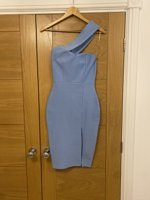
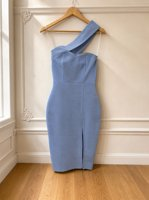
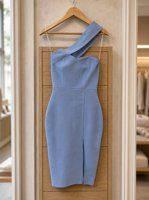
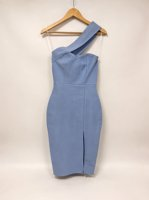
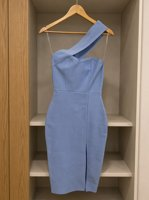
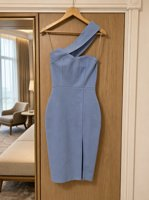
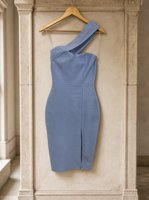

Full size: [Original](images/blue-dress.jpg) · [paris-apartment](output/01-listing-paris-apartment.png) · [fashion-boutique](output/01-listing-fashion-boutique.png) · [minimal-studio](output/01-listing-minimal-studio.png) · [luxury-wardrobe](output/01-listing-luxury-wardrobe.png) · [hotel-suite](output/01-listing-hotel-suite.png) · [stone-townhouse](output/01-listing-stone-townhouse.png)

In [3]:
DRESS = IMAGES / "blue-dress.jpg"
BACKGROUNDS = {
    "paris-apartment": "a bright Parisian apartment with pale walls, subtle molding, and warm oak flooring",
    "fashion-boutique": "an elegant independent fashion boutique with neutral decor and soft window light",
    "minimal-studio": "a clean warm-white photography studio with a seamless backdrop and soft diffused lighting",
    "luxury-wardrobe": "a refined walk-in wardrobe with muted finishes and an uncluttered editorial look",
    "hotel-suite": "a sophisticated boutique hotel suite with tasteful neutral furnishings and natural daylight",
    "stone-townhouse": "a chic European townhouse interior with pale stone details and understated styling",
}


def listing(background: str) -> str:
    return (f"Edit only the background of this secondhand clothing photo. Place the clothing item in {background}. "
            "Keep the item and every foreground detail unchanged: shape, cut, proportions, color, pattern, fabric texture, seams, "
            "labels, embellishments, condition, and fit. Do not redesign, retouch, reshape, recolor, or add anything to the item. "
            "Match the original perspective and use physically realistic lighting and shadows. "
            "An authentic professional product photograph for an online resale listing. No text, logos, borders, or watermarks.")


with ThreadPoolExecutor(max_workers=6) as pool:
    jobs = {name: pool.submit(mai.edit, listing(text), [DRESS], f"01-listing-{name}", FLASH) for name, text in BACKGROUNDS.items()}
listings = {name: job.result() for name, job in jobs.items()}
show({"Original": DRESS, **listings}, height=200)

**What to look for:** the dress first: hemline, buttons, fabric pattern, and any wear should match the original in all six. Then the background: does the light on the dress match the room, and does the shadow fall where the room's light says it should? A dress that changes is a returned order.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 2. Can Flash brainstorm art directions from a customer's keywords?

Mood boards are for exploring, so speed matters more than polish. We pair the customer's keywords with style modifiers to make six art directions, then generate all six at once. A fixed seed keeps the same six directions on every run.

   02-mood-warm-plants: MAI-Image-2.6-Flash | 11.2 s | 1024×1024
   02-mood-midnight-comfortable: MAI-Image-2.6-Flash | 11.4 s | 1024×1024
   02-mood-analog-feminine: MAI-Image-2.6-Flash | 11.4 s | 1024×1024
   02-mood-luxury-comfortable: MAI-Image-2.6-Flash | 11.3 s | 1024×1024
   02-mood-precision-plants: MAI-Image-2.6-Flash | 11.6 s | 1024×1024
   02-mood-calm-feminine: MAI-Image-2.6-Flash | 12.3 s | 1024×1024



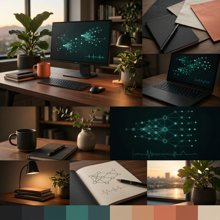
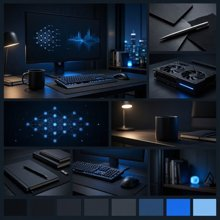
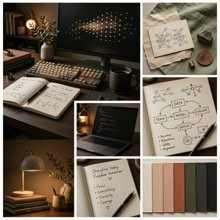
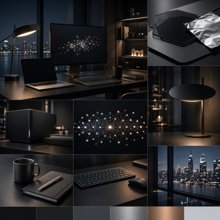
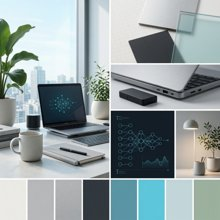
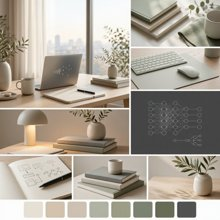

Full size: [warm-plants](output/02-mood-warm-plants.png) · [midnight-comfortable](output/02-mood-midnight-comfortable.png) · [analog-feminine](output/02-mood-analog-feminine.png) · [luxury-comfortable](output/02-mood-luxury-comfortable.png) · [precision-plants](output/02-mood-precision-plants.png) · [calm-feminine](output/02-mood-calm-feminine.png)

In [4]:
import random

STYLE_MODIFIERS = [
    ("precision", "white ceramic, brushed aluminum, cool daylight, cyan accents"),
    ("warm", "walnut desk, soft amber light, plants, coral and teal accents"),
    ("midnight", "charcoal surfaces, focused monitor glow, electric blue accents"),
    ("calm", "pale ash wood, matte white tools, diffused morning light, sage accents"),
    ("analog", "notebooks, technical sketches, mechanical keyboard, moss and rust tones"),
    ("luxury", "smoked glass, black metal, sculptural lighting, silver accents"),
    ("industrial", "raw concrete, exposed steel, harsh overhead light, rust accents"),
    ("coastal", "bleached driftwood, linen textures, soft diffused light, seafoam accents"),
]
CUSTOMER_KEYWORDS = ["feminine", "plants", "comfortable"]  # Replace with the customer's own words

shuffle = random.Random(2026)
modifiers = shuffle.sample(STYLE_MODIFIERS, 6)
keywords = shuffle.sample(CUSTOMER_KEYWORDS * 2, 6)
DIRECTIONS = {f"{style}-{word}": f"{word}-inspired workspace, {details}" for (style, details), word in zip(modifiers, keywords)}


def mood_board(direction: str) -> str:
    return ("A sophisticated visual mood board for the concept 'The AI Engineer's desk'. "
            f"Art direction: {direction}. A cohesive editorial collage with one hero workspace image and smaller supporting frames showing "
            "tactile materials, desk objects, computing hardware, abstract neural-network diagrams, lighting details, and a restrained row "
            "of color swatches. Photorealistic, precise grid, generous spacing, coherent lighting, square composition. "
            "No people, brand logos, watermarks, captions, labels, or legible text.")


with ThreadPoolExecutor(max_workers=6) as pool:
    jobs = {name: pool.submit(mai.generate, mood_board(text), f"02-mood-{name}", FLASH) for name, text in DIRECTIONS.items()}
boards = {name: job.result() for name, job in jobs.items()}
show(boards, height=220)

**What to look for:** six boards that feel different from each other, each true to its direction (a "warm" board in amber, a "midnight" board in blue glow). Check the "no legible text" rule too: stray words on a mood board are a common slip.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 3. Can MAI-Image-2.6 fix one flaw and leave everything else alone?

A product photo of a car has a fingerprint smudge on the lens. We ask MAI-Image-2.6 to remove only that. The real test of an edit is what *doesn't* change.

   03-car-smudge-removed: MAI-Image-2.6 | 18.6 s | 768×1360



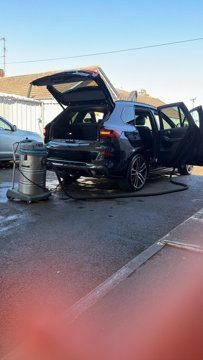
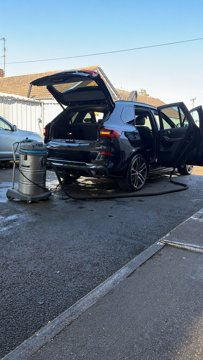

Full size: [Before](images/car2.png) · [After](output/03-car-smudge-removed.png)

In [5]:
CAR = IMAGES / "car2.png"
fixed = mai.edit("Remove the finger blur mark while preserving every other detail of this photograph.", [CAR], "03-car-smudge-removed", HERO)
show({"Before": CAR, "After": fixed}, height=360)

**What to look for:** the smudge should be gone. Then check reflections on the paint, the badge, the wheels, and the background: none of them should move, sharpen, or change color.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 4. Does the same character survive three new scenes?

**Bit** is a plush raccoon mascot. With one reference image and a description of what must not change, we ask MAI-Image-2.6 to place Bit in three event scenes.

> 🔮 **Guess first:** which detail will slip first: the eye mask, the ears, or the logo on the shirt?

   04-bit-conference-stage: MAI-Image-2.6 | 19.9 s | 880×1184
   04-bit-conference-booth: MAI-Image-2.6 | 19.8 s | 880×1184
   04-bit-hackathon: MAI-Image-2.6 | 22.5 s | 880×1184



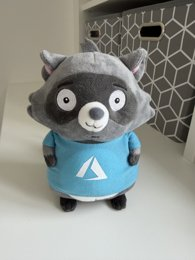
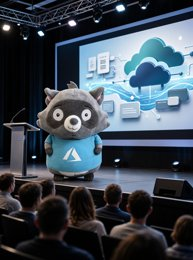
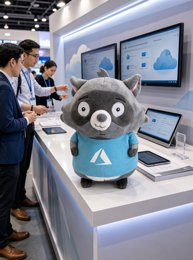
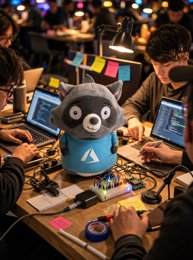

Full size: [Reference](images/bit1.png) · [conference-stage](output/04-bit-conference-stage.png) · [conference-booth](output/04-bit-conference-booth.png) · [hackathon](output/04-bit-hackathon.png)

In [6]:
BIT = IMAGES / "bit1.png"
BIT_IDENTITY = ("Use the provided image as the exact character reference for Bit. Preserve Bit as the same gray plush raccoon character: "
                "identical face, dark eye mask, large round white eyes, small ears with pink interiors, gray fur, body proportions, "
                "turquoise Azure-logo shirt, friendly expression, and soft plush-toy texture. Do not redesign, recolor, or replace the character. ")
BIT_SCENES = {
    "conference-stage": ("A photorealistic event photograph of Bit presenting on a modern technical conference stage, beside a large screen showing "
                         "abstract cloud architecture diagrams with no legible text. Stage lighting, a lectern, and an audience seen from behind."),
    "conference-booth": ("A photorealistic event photograph of Bit welcoming attendees at a polished technology conference booth, with demo monitors, "
                         "a clean counter, subtle cloud visuals with no legible text, and attendees nearby. Bit is clearly the host."),
    "hackathon": ("A photorealistic candid photograph of Bit at an energetic hackathon, seated with a small team around laptops, cables, sticky notes, "
                  "and prototype electronics, in warm late-night light. Bit is clearly part of the team."),
}
scenes = {name: mai.edit(BIT_IDENTITY + prompt, [BIT], f"04-bit-{name}", HERO) for name, prompt in BIT_SCENES.items()}
show({"Reference": BIT, **scenes}, height=260)

**What to look for:** compare each scene with the reference, feature by feature: mask, eyes, ear color, fur, proportions, shirt color, and logo. A character that is "close" is not the same character to a brand team.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 5. How consistent is the character across 27 test cases?

Three scenes is a demo; a brand team needs a test. This matrix varies one thing at a time (repeatability, camera angle, lighting, occlusion and scale, wardrobe, lens, object interaction, how much we describe the character, and pose) so we can see *where* consistency breaks. The run writes a contact sheet and a blank scorecard to `output/`.

> 🔮 **Guess first:** which group will score worst?

In [7]:
BIT_IDENTITY_SHORT = "Keep Bit recognizably the same character as the reference image, including the face, gray fur, proportions, turquoise shirt, and Azure logo. "
GREY = "with soft even lighting and a plain light-gray background"
CASES = {
    **{f"repeatability-{n}": f"A neutral full-body studio photograph of Bit standing upright and facing the camera, centered, {GREY}, with no props or text." for n in (1, 2, 3)},
    "angle-front": f"A neutral full-body studio photograph of Bit viewed directly from the front, {GREY}.",
    "angle-side-profile": f"A neutral full-body studio photograph of Bit in a clear left-side profile, {GREY}.",
    "angle-rear-three-quarter": f"A neutral full-body studio photograph of Bit from a rear three-quarter angle, turning its face toward the camera, {GREY}.",
    "light-daylight": "A full-body photograph of Bit facing the camera beside a large window in natural daylight, in a simple neutral room.",
    "light-conference-stage": "A full-body photograph of Bit facing the camera under cool conference stage lighting, on a minimal dark stage.",
    "light-warm-low": "A full-body photograph of Bit facing the camera in warm low indoor light, with facial features, colors, and clothing clearly visible.",
    "scale-close-up": "A close-up portrait of Bit facing the camera, framed from the chest up against a plain neutral background.",
    "scale-behind-desk": "A photograph of Bit facing the camera behind a simple desk that hides the lower body, in a neutral office.",
    "scale-distant-crowd": "A wide conference photograph with Bit facing the camera, fully visible at a distance among a small crowd, recognizable and unobstructed.",
    "wardrobe-lanyard": "A full-body conference portrait of Bit wearing a badge lanyard over the original turquoise Azure-logo shirt, shirt and logo unchanged and visible.",
    "wardrobe-open-jacket": "A full-body portrait of Bit in an open lightweight jacket over the original turquoise Azure-logo shirt, shirt and logo unchanged.",
    "wardrobe-backpack": "A full-body portrait of Bit wearing a small backpack, with the turquoise Azure-logo shirt unobstructed and unchanged.",
    "lens-24mm-wide": "A full-body environmental portrait of Bit with a 24mm wide-angle lens from a moderate distance, in a simple conference hallway, without distortion.",
    "lens-50mm-normal": "A three-quarter portrait of Bit with a natural 50mm lens perspective against a simple neutral conference background.",
    "lens-85mm-telephoto": "A chest-up portrait of Bit with an 85mm portrait lens, gentle background blur, and undistorted proportions.",
    "object-microphone": "A full-body photograph of Bit holding a handheld microphone and facing the camera on a simple conference stage.",
    "object-laptop": "A three-quarter photograph of Bit typing on an open laptop at a simple desk while looking toward the camera.",
    "object-mug": "A full-body photograph of Bit carrying a plain ceramic mug in one paw in a neutral office.",
    "pose-standing": f"A neutral full-body studio photograph of Bit standing upright, arms relaxed, facing the camera, {GREY}.",
    "pose-waving": f"A full-body studio photograph of Bit facing the camera and waving with one paw, with natural anatomy, {GREY}.",
    "pose-walking": "A full-body photograph of Bit walking toward the camera in a simple conference hallway, proportions and features recognizable.",
}
PRESENTING = "A full-body photograph of Bit presenting beside a laptop in a modern conference room with soft daylight."
IDENTITY = {"prompt-full-identity": BIT_IDENTITY, "prompt-short-identity": BIT_IDENTITY_SHORT, "prompt-reference-only": ""}
MATRIX = {name: BIT_IDENTITY + prompt for name, prompt in CASES.items()} | {name: text + PRESENTING for name, text in IDENTITY.items()}
assert len(MATRIX) == 27

with ThreadPoolExecutor(max_workers=4) as pool:
    jobs = {name: pool.submit(mai.edit, prompt, [BIT], f"05-matrix-{name}", HERO) for name, prompt in MATRIX.items()}
matrix = {name: job.result() for name, job in jobs.items()}
print(f"{len(matrix)} of {len(MATRIX)} cases ready")

   05-matrix-repeatability-1: MAI-Image-2.6 | 17.0 s | 880×1184
   05-matrix-repeatability-2: MAI-Image-2.6 | 18.6 s | 880×1184
   05-matrix-angle-front: MAI-Image-2.6 | 18.6 s | 880×1184
   05-matrix-repeatability-3: MAI-Image-2.6 | 19.1 s | 880×1184
   05-matrix-angle-side-profile: MAI-Image-2.6 | 19.6 s | 880×1184
   05-matrix-angle-rear-three-quarter: MAI-Image-2.6 | 17.4 s | 880×1184
   05-matrix-light-daylight: MAI-Image-2.6 | 19.2 s | 880×1184
   05-matrix-light-conference-stage: MAI-Image-2.6 | 18.6 s | 880×1184
   05-matrix-light-warm-low: MAI-Image-2.6 | 18.8 s | 880×1184
   05-matrix-scale-close-up: MAI-Image-2.6 | 19.4 s | 880×1184
   05-matrix-scale-behind-desk: MAI-Image-2.6 | 19.4 s | 880×1184
   05-matrix-scale-distant-crowd: MAI-Image-2.6 | 21.0 s | 880×1184
   05-matrix-wardrobe-lanyard: MAI-Image-2.6 | 20.3 s | 880×1184
   05-matrix-wardrobe-open-jacket: MAI-Image-2.6 | 18.2 s | 880×1184
   05-matrix-wardrobe-backpack: MAI-Image-2.6 | 18.6 s | 880×1184
   05-matrix-l

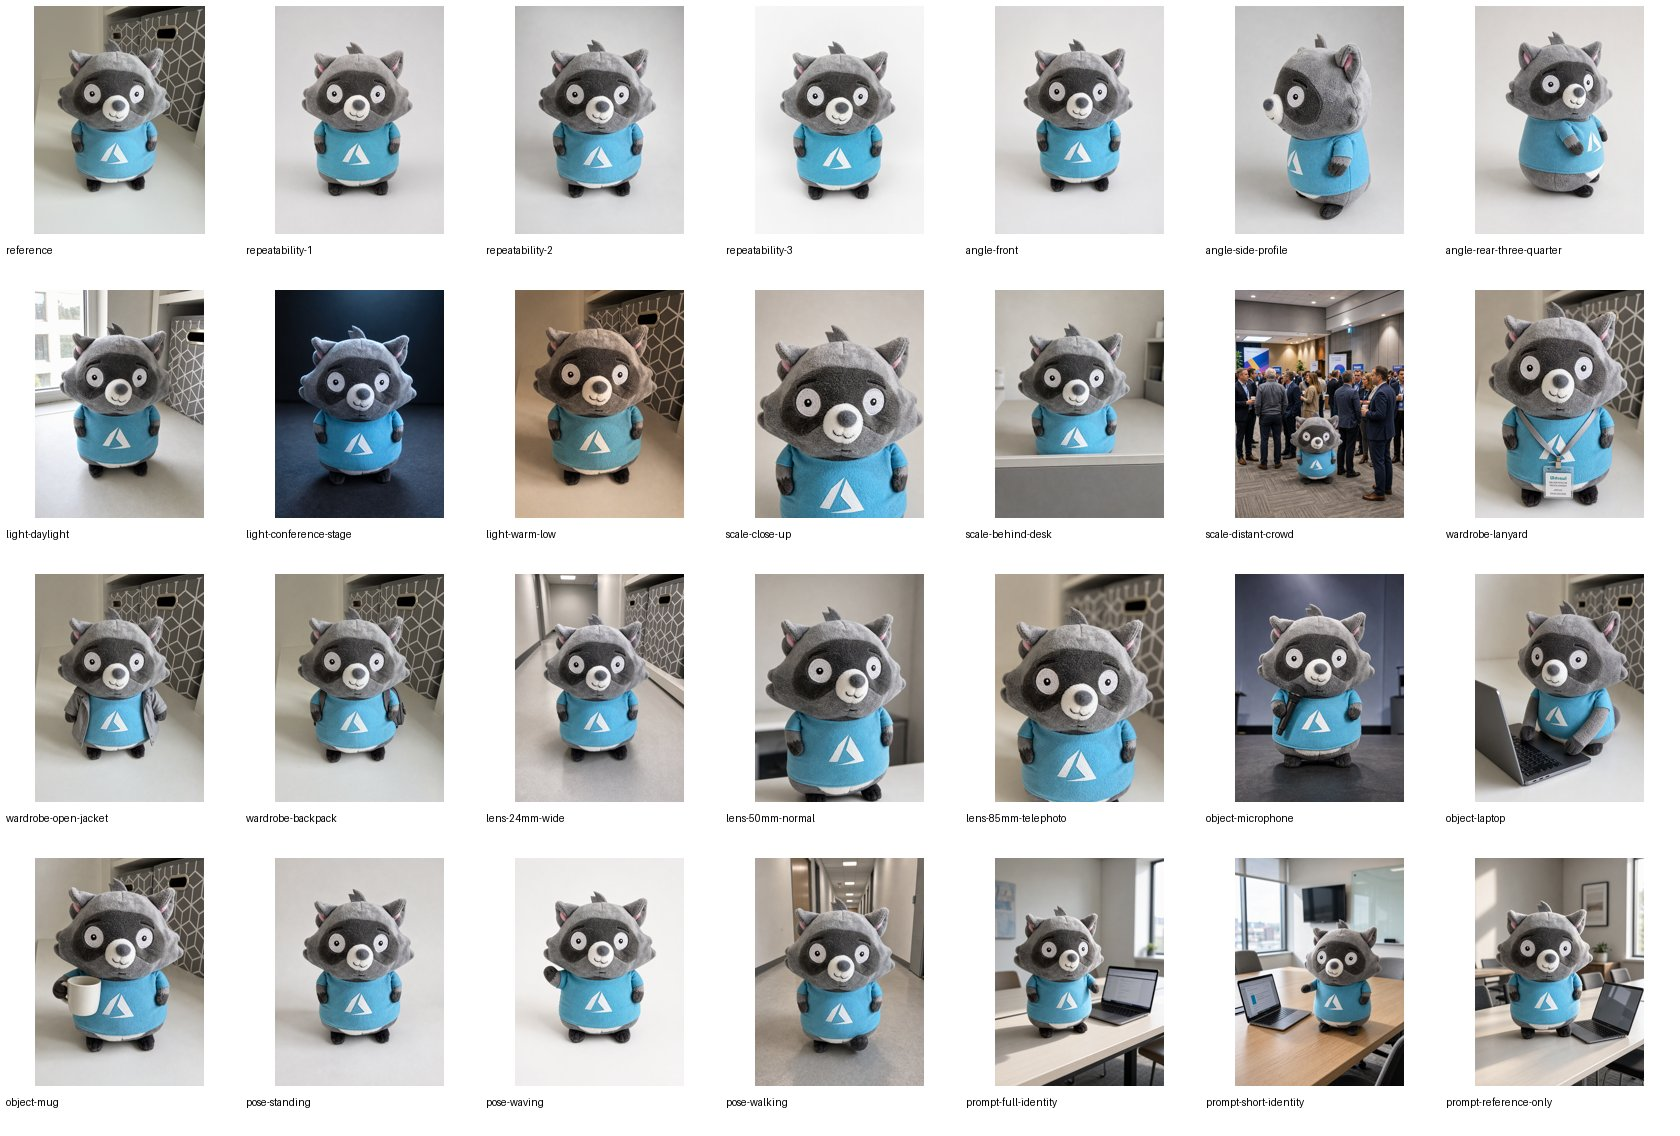

Score each case 0-2 per field in output/05-scorecard.csv


In [8]:
import csv
import textwrap

from IPython.display import Image as Picture, display
from PIL import Image, ImageDraw, ImageOps

tiles = [("reference", BIT), *matrix.items()]
TILE, LABEL, COLUMNS = 240, 44, 7
rows = -(-len(tiles) // COLUMNS)
sheet = Image.new("RGB", (COLUMNS * TILE, rows * (TILE + LABEL)), "white")
draw = ImageDraw.Draw(sheet)
for i, (name, path) in enumerate(tiles):
    x, y = (i % COLUMNS) * TILE, (i // COLUMNS) * (TILE + LABEL)
    with Image.open(path) as picture:
        thumb = ImageOps.contain(picture.convert("RGB"), (TILE - 12, TILE - 12))
    sheet.paste(thumb, (x + (TILE - thumb.width) // 2, y + (TILE - thumb.height) // 2))
    draw.multiline_text((x + 6, y + TILE + 4), "\n".join(textwrap.wrap(name, 30)), fill="black")

sheet_path = mai.output / "05-contact-sheet.jpg"
sheet.save(sheet_path, quality=85)
display(Picture(filename=str(sheet_path), width=1000))

FIELDS = ["face", "eyes", "ears", "fur", "proportions", "shirt", "logo", "overall", "scene", "notes"]
scorecard = mai.output / "05-scorecard.csv"
with scorecard.open("w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["case", *FIELDS])
    writer.writerows([name, *[""] * len(FIELDS)] for name in matrix)
print(f"Score each case 0-2 per field in output/{scorecard.name}")

**What to look for:** read the sheet by row. Repeatability should look like triplets; side profile and rear angles usually slip first; wide lenses and crowds shrink the details a brand team checks. The three `prompt-` cases show how much the written identity helps compared with the reference image alone. Fill in the scorecard (0 = wrong, 1 = close, 2 = right) to turn impressions into a number we can compare when the next model ships.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

### 🔧 Break it on purpose

The edits API takes **one to five** reference images. What happens if we send six?

In [9]:
if MODE == "live":
    try:
        mai.edit("Combine these photos into one scene.", [CAR] * 6, "break-six-references", FLASH)
    except RuntimeError as error:
        print(error)
else:
    print("Replay mode: in live mode the service answers 400 and says how many reference images it accepts.")

400 from MAI-Image-2.6-Flash. The model didn't accept a setting. Check the size (each side 768 or more, 2,359,296 pixels at most), the image type (PNG or JPEG), and the options.
Invalid request. Error => Only 1 to 5 image files are supported for edit requests.


The request is rejected before any picture is made, and the message says what to change. Combine references into fewer images, or keep the five that matter most, putting the most important first.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 6. Which model should each job use?

### Scoreboard

How long each picture took, by model, from the run log.

In [10]:
import statistics

for model in (FLASH, HERO):
    times = [entry["seconds"] for entry in mai.log.values() if entry["model"] == model]
    if times:
        print(f"{model:22} {len(times):3} pictures | median {statistics.median(times):5.1f} s | slowest {max(times):5.1f} s")

MAI-Image-2.6-Flash     12 pictures | median  14.2 s | slowest  16.7 s
MAI-Image-2.6           31 pictures | median  18.8 s | slowest  22.5 s


- **[MAI-Image-2.6-Flash](../../4-models/mai-image-2.6-flash/):** volume and exploration: listing backgrounds, mood boards, drafts, and routine edits, especially when someone is waiting.
- **[MAI-Image-2.6](../../4-models/mai-image-2.6/):** work people will study: careful edits where nothing else may change, a brand character across scenes, text-heavy designs, and final versions.
- **Not sure?** Draft on Flash, finish on MAI-Image-2.6. The [Flash capsule](../../4-models/mai-image-2.6-flash/) shows that pattern with a blind taste test.

Speeds depend on region, time of day, and prompt, so share numbers from your own run. For cost, use the [pricing page](https://aka.ms/MAIModelPricing).

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## Your Turn to Explore

- **Your own listing.** Replace `DRESS` with one of your product photos (PNG or JPEG) and the backgrounds with your brand's settings.
- **A harder character.** Swap `BIT` for your mascot and rerun only the `angle-` and `lens-` cases.
- **Flash on the matrix.** Change `HERO` to `FLASH` in section 5 and compare the contact sheets.

In [11]:
# Your experiment here. Try: show({"Mine": mai.generate("...", "my-picture", FLASH)})

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## What We Did

- ✅ Made six listing backgrounds and six mood boards at once on Flash
- ✅ Fixed one flaw in a photo with MAI-Image-2.6 and checked that nothing else changed
- ✅ Kept a character the same across scenes, then built a 27-case contact sheet and scorecard

➡️ **Next:** go deeper in [MAI-Image-2.6 · 01 · Text and design](../../4-models/mai-image-2.6/mai-image-2.6-01-text-and-design.ipynb).

Stuck? [Open an issue](https://github.com/microsoft-foundry/model-releases/issues/new) with the failing cell's output.

**Learn more:** [Use MAI image models in Microsoft Foundry](https://learn.microsoft.com/azure/foundry/foundry-models/how-to/use-foundry-models-mai-image) · [Image Generation primer](../../3-primers/image-generation.md) · [MAI model pricing](https://aka.ms/MAIModelPricing)